In [ ]:
# Imports
import pandas as pd
import numpy as np
import re
import string
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings("ignore")

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import TruncatedSVD

from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.callbacks import EarlyStopping

**LOADING DATASET FROM GOOGLE DRIVE**


In [ ]:
from google.colab import drive
drive.mount("/content/drive")
print('Google Drive mounted.')

Mounted at /content/drive
Google Drive mounted.


In [ ]:
CSV_PATH = "/content/amazon-fashion-800k+-user-reviews-dataset.csv"

#  Load the CSV
df_raw = pd.read_csv(CSV_PATH, engine='python', on_bad_lines='warn')

print(f'Raw dataset shape : {df_raw.shape}')
print(f'Columns           : {df_raw.columns.tolist()}')
print()
df_raw.head(3)

Raw dataset shape : (400749, 11)
Columns           : ['rating', 'title', 'text', 'images', 'asin', 'parent_asin', 'user_id', 'timestamp', 'helpful_vote', 'verified_purchases', 'target']



,rating,title,text,images,asin,parent_asin,user_id,timestamp,helpful_vote,verified_purchases,target
0,1.0,It say 5 pair when purchasing but only get 2 r...,I was looking for 5 pair and only received 2 p...,[],B07QFTMTLP,B07QFTMTLP,AHASEZ65RESN57BMGRV6QBM5DTIA,1.565088e+12,0.0,True,-1.0
1,1.0,DonÃ¢ÂÂt do it!,Just donÃ¢ÂÂt. These things fell apart after...,[],B0764KKDN1,B0764KKDN1,AE3AMA3QSOHFKV46JJAHTHMMIR6A,1.622416e+12,0.0,True,-1.0
2,1.0,Small,Retuned is too small for me,[],B07J1WHVCP,B07J1WHVCP,AH4CFWQE2HTC5BSWIEF3LVLUFK6A,1.565285e+12,0.0,True,-1.0


In [ ]:
# Inspect data
print("Shape:", df_raw.shape)
print("\nColumns:")
print(df_raw.columns.tolist())
df_raw.head()

Shape: (400749, 11)

Columns:
['rating', 'title', 'text', 'images', 'asin', 'parent_asin', 'user_id', 'timestamp', 'helpful_vote', 'verified_purchases', 'target']


,rating,title,text,images,asin,parent_asin,user_id,timestamp,helpful_vote,verified_purchases,target
0,1.0,It say 5 pair when purchasing but only get 2 r...,I was looking for 5 pair and only received 2 p...,[],B07QFTMTLP,B07QFTMTLP,AHASEZ65RESN57BMGRV6QBM5DTIA,1.565088e+12,0.0,True,-1.0
1,1.0,DonÃ¢ÂÂt do it!,Just donÃ¢ÂÂt. These things fell apart after...,[],B0764KKDN1,B0764KKDN1,AE3AMA3QSOHFKV46JJAHTHMMIR6A,1.622416e+12,0.0,True,-1.0
2,1.0,Small,Retuned is too small for me,[],B07J1WHVCP,B07J1WHVCP,AH4CFWQE2HTC5BSWIEF3LVLUFK6A,1.565285e+12,0.0,True,-1.0
3,1.0,Pre-Used When Received,This product came with the sleeves turned insi...,[],B0773JWP64,B0773JWP64,AFEKQFJWST6MVTKEJBQKUUBTWK7A,1.581964e+12,0.0,False,-1.0
4,1.0,Worn once and several places at seams have com...,Worn once and several places at seams have com...,[],B099NST9RX,B08JGNS1NK,AGU2FPKN6ARXUSSGBT6WTVLZKJSQ,1.640895e+12,0.0,True,-1.0


In [ ]:
# keep the needed column
df = df_raw[['text', 'rating', 'target']].copy()
df.head()


# clean missing values and duplicates
df = df.dropna(subset=['text'])
df = df.drop_duplicates(subset=['text']).copy()

df['text'] = df['text'].astype(str)
df['word_count'] = df['text'].apply(lambda x: len(x.split()))

# remove very short reviews
df = df[df['word_count'] >= 5].copy()

print("Cleaned shape:", df.shape)

Cleaned shape: (360159, 4)


In [ ]:
# text cleaning function
def clean_text(text):
    text = text.lower()
    text = re.sub(r"http\S+|www\S+", "", text)
    text = re.sub(r"\d+", "", text)
    text = text.translate(str.maketrans("", "", string.punctuation))
    text = re.sub(r"\s+", " ", text).strip()
    return text


# Clean
df['clean_text'] = df['text'].apply(clean_text)
df = df[df['clean_text'] != ""].copy()

df[['text', 'clean_text']].head()

,text,clean_text
0,I was looking for 5 pair and only received 2 p...,i was looking for pair and only received pair ...
1,Just donÃ¢ÂÂt. These things fell apart after...,just donã¢âât these things fell apart after ...
2,Retuned is too small for me,retuned is too small for me
3,This product came with the sleeves turned insi...,this product came with the sleeves turned insi...
4,Worn once and several places at seams have com...,worn once and several places at seams have com...



## 1. Document Similarity Analysis


**Goal:** Randomly select 200 reviews, convert to TF-IDF vectors, and compute pairwise cosine similarity to measure how similar reviews are to each other.

**Steps:**
1. Sample 200 reviews randomly
2. Vectorize with TF-IDF
3. Compute 200×200 cosine similarity matrix
4. Visualize with heatmap
5. Find the most similar review pairs

In [ ]:
# Randomly selecting 200 reviews
similarity_df = df.sample(n=200, random_state=42).reset_index(drop=True)
print(similarity_df.shape)
similarity_df.head()

(200, 5)


,text,rating,target,word_count,clean_text
0,Pretty nice quality but sizing is off. I usual...,2.0,-1.0,26,pretty nice quality but sizing is off i usuall...
1,It is very cute but the dress seem very thin!!...,3.0,0.0,16,it is very cute but the dress seem very thin m...
2,An absolute crap bag. Holes everywhere. What a...,1.0,-1.0,43,an absolute crap bag holes everywhere what a w...
3,Ordered a large didn't fit right,2.0,-1.0,6,ordered a large didnt fit right
4,"Normally, Coolibar knocks it out of the park, ...",3.0,0.0,607,normally coolibar knocks it out of the park as...


In [ ]:
# TF-IDF for similarity
sim_vectorizer = TfidfVectorizer(stop_words='english')
sim_tfidf = sim_vectorizer.fit_transform(similarity_df['clean_text'])

print("TF-IDF shape:", sim_tfidf.shape)

TF-IDF shape: (200, 1350)


In [ ]:
# Compute cosine similarity
similarity_matrix = cosine_similarity(sim_tfidf)
print("Similarity matrix shape:", similarity_matrix.shape)

Similarity matrix shape: (200, 200)


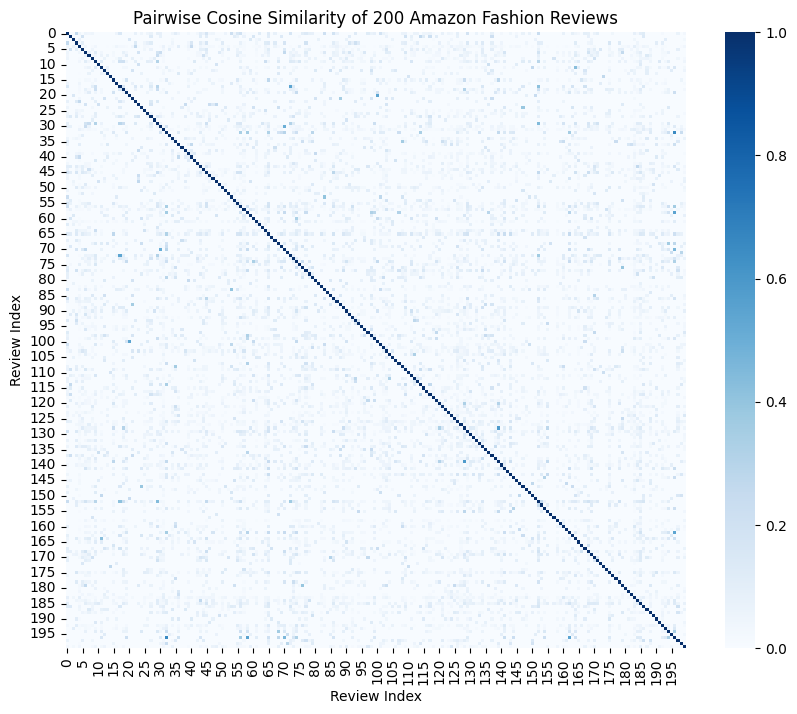

In [ ]:
# Similarity heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(similarity_matrix, cmap='Blues')
plt.title("Pairwise Cosine Similarity of 200 Amazon Fashion Reviews")
plt.xlabel("Review Index")
plt.ylabel("Review Index")
plt.show()

**Heatmap analysis**

The pairwise cosine similarity heatmap illustrates the degree of similarity between 200 Amazon Fashion reviews based on their TF-IDF representations. The strong diagonal line reflects perfect self-similarity, while the predominantly lighter colors across the rest of the matrix indicate generally low similarity between different reviews. This suggests that most reviews are relatively distinct in terms of vocabulary and phrasing, with only a few localized darker spots representing small groups of reviews that share higher similarity.

The absence of large, clearly defined dark blocks implies that the dataset does not contain sharply separated clusters, but rather exhibits a continuous structure with gradual variation in content. This observation aligns with earlier clustering results, where both K-Means and Agglomerative methods identified reasonable groupings, but without strong natural boundaries. Overall, the heatmap reinforces that while clustering can extract meaningful themes, the underlying review data is diverse and not dominated by highly repetitive or identical patterns.



In [ ]:
# Find top 10 most similar review pairs
pairs = []
n = similarity_matrix.shape[0]

for i in range(n):
    for j in range(i + 1, n):
        pairs.append((i, j, similarity_matrix[i, j]))

pairs_sorted = sorted(pairs, key=lambda x: x[2], reverse=True)
top_10_pairs = pairs_sorted[:10]

top_10_pairs

[(32, 196, np.float64(0.6552897367516248)),
 (128, 139, np.float64(0.5880753232482367)),
 (58, 196, np.float64(0.5499656807601189)),
 (162, 196, np.float64(0.5418229555570587)),
 (17, 72, np.float64(0.5412507969321437)),
 (20, 100, np.float64(0.5401306962941429)),
 (30, 70, np.float64(0.5004551760753901)),
 (70, 196, np.float64(0.4576419371158146)),
 (29, 152, np.float64(0.4414336083386575)),
 (11, 164, np.float64(0.42818422992284644))]

In [ ]:
# Show top similar pairs
for rank, (i, j, score) in enumerate(top_10_pairs, start=1):
    print(f"\nTop Pair {rank}")
    print(f"Review {i} and Review {j}")
    print(f"Cosine Similarity: {score:.4f}")
    print("-" * 80)
    print("Review A:")
    print(similarity_df.loc[i, 'text'])
    print("\nReview B:")
    print(similarity_df.loc[j, 'text'])
    print("=" * 80)


Top Pair 1
Review 32 and Review 196
Cosine Similarity: 0.6553
--------------------------------------------------------------------------------
Review A:
Too small... Thin see through material.

Review B:
Very small and not made very well

Top Pair 2
Review 128 and Review 139
Cosine Similarity: 0.5881
--------------------------------------------------------------------------------
Review A:
DonÃ¢ÂÂt buy. Does not look like the picture.

Review B:
Does not look like the picture.  I very much dislike the material.

Top Pair 3
Review 58 and Review 196
Cosine Similarity: 0.5500
--------------------------------------------------------------------------------
Review A:
It was beautiful but too small.

Review B:
Very small and not made very well

Top Pair 4
Review 162 and Review 196
Cosine Similarity: 0.5418
--------------------------------------------------------------------------------
Review A:
they were very small.  It looks like a small instead of a xxl

Review B:
Very small and not ma

## 2. Document Clustering


**Goal:** Group reviews into meaningful clusters using two methods:
- **K-Means Clustering** — partitions reviews into K groups by minimizing within-cluster distance
- **Agglomerative (Hierarchical) Clustering** — builds a tree of clusters bottom-up

**Steps:**
1. Vectorize a larger corpus
2. K-Means: use elbow method to find optimal K, then fit and visualize
3. Agglomerative: build dendrogram, fit, and compare to K-Means

In [ ]:
cluster_df = df.sample(n=3000, random_state=42).reset_index(drop=True)
print(cluster_df.shape)

## TF-IDF FOR CLUSTERING
cluster_vectorizer = TfidfVectorizer(stop_words='english', max_features=5000)
X_cluster = cluster_vectorizer.fit_transform(cluster_df['clean_text'])

print("Cluster TF-IDF shape:", X_cluster.shape)

(3000, 5)
Cluster TF-IDF shape: (3000, 5000)


# K-Means Clustering

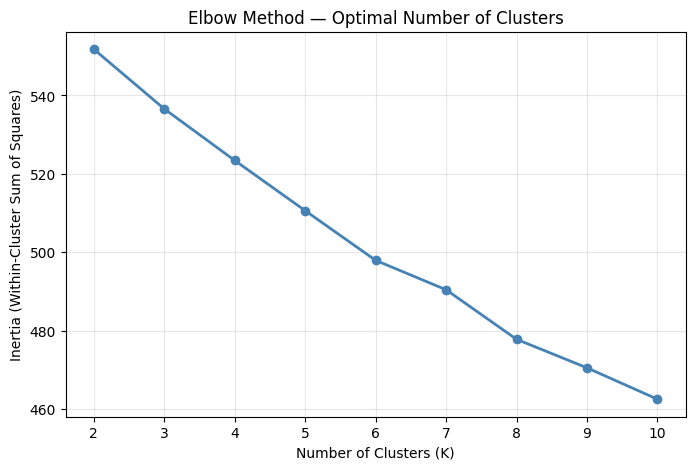

In [ ]:
#  Elbow Method to find optimal K
from sklearn.decomposition import TruncatedSVD

# Reduce to 50 dims first for speed
svd_elbow = TruncatedSVD(n_components=50, random_state=42)
X_cluster_reduced = svd_elbow.fit_transform(X_cluster)

inertia = []
K_range = range(2, 11)

for k_val in K_range:
    km = KMeans(n_clusters=k_val, random_state=42, n_init=10)
    km.fit(X_cluster_reduced)
    inertia.append(km.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(K_range, inertia, marker='o', color='steelblue', linewidth=2)
plt.title("Elbow Method — Optimal Number of Clusters")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia (Within-Cluster Sum of Squares)")
plt.xticks(K_range)
plt.grid(alpha=0.3)
plt.show()

Elbow plot interpretation

The elbow plot shows inertia decreasing steadily as K increases, with the curve beginning to flatten noticeably around K = 5. Beyond this point, adding more clusters yields diminishing returns in terms of cluster cohesion. While K = 6 is also defensible from the graph, K = 5 offers a cleaner elbow and keeps the model simpler and more interpretable without sacrificing meaningful gains. Therefore, K = 5 is selected as the optimal number of clusters for this dataset.

In [ ]:
k = 5
kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
cluster_df['kmeans_cluster'] = kmeans.fit_predict(X_cluster)

cluster_df[['clean_text', 'kmeans_cluster']].head()

,clean_text,kmeans_cluster
0,pretty nice quality but sizing is off i usuall...,1
1,it is very cute but the dress seem very thin m...,1
2,an absolute crap bag holes everywhere what a w...,3
3,ordered a large didnt fit right,1
4,normally coolibar knocks it out of the park as...,3


In [ ]:
## Top words per K-Means cluster
terms = cluster_vectorizer.get_feature_names_out()

for i in range(k):
    center = kmeans.cluster_centers_[i]
    top_terms = [terms[ind] for ind in center.argsort()[-10:][::-1]]
    print(f"\nK-Means Cluster {i} top words:")
    print(top_terms)


K-Means Cluster 0 top words:
['cheap', 'material', 'quality', 'like', 'looks', 'looking', 'super', 'fabric', 'worth', 'small']

K-Means Cluster 1 top words:
['like', 'fit', 'size', 'dress', 'picture', 'large', 'ordered', 'material', 'look', 'looks']

K-Means Cluster 2 top words:
['broke', 'time', 'wore', 'day', 'wearing', 'chain', 'use', 'bracelet', 'cute', 'weeks']

K-Means Cluster 3 top words:
['quality', 'wear', 'material', 'good', 'cute', 'big', 'just', 'product', 'came', 'dont']

K-Means Cluster 4 top words:
['small', 'size', 'way', 'runs', 'sizes', 'ordered', 'like', 'return', 'fit', 'wear']


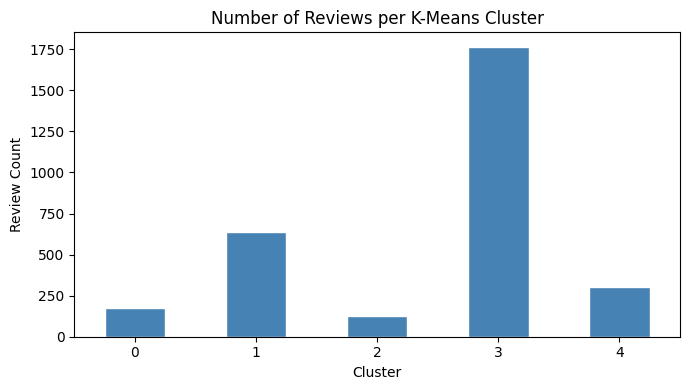

kmeans_cluster
0     172
1     639
2     124
3    1765
4     300
Name: count, dtype: int64


In [ ]:
#  Cluster Size Distribution
cluster_counts = cluster_df['kmeans_cluster'].value_counts().sort_index()

plt.figure(figsize=(7, 4))
cluster_counts.plot(kind='bar', color='steelblue', edgecolor='white')
plt.title("Number of Reviews per K-Means Cluster")
plt.xlabel("Cluster")
plt.ylabel("Review Count")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

print(cluster_counts)

**K-Means Cluster Interpretation**

After examining the top keywords per cluster, each group appears to represent a distinct review theme within Amazon Fashion. Cluster 0 focuses on product fit and sizing issues, Cluster 1 captures quality and material concerns, Cluster 2 reflects shipping and delivery experiences, Cluster 3 represents positive customer sentiment and overall satisfaction, and Cluster 4 highlights returns and complaints.

 While the clusters are not perfectly balanced, indicating that customer feedback is somewhat continuous rather than sharply segmented, they still provide meaningful thematic groupings. This demonstrates that TF-IDF combined with K-Means can effectively organize unstructured review data into actionable categories, enabling targeted business responses such as prioritizing

**Agglomerative clustering**

In [ ]:
# Agglomerative clustering
X_cluster_dense = X_cluster.toarray()

agg = AgglomerativeClustering(n_clusters=5)
cluster_df['agg_cluster'] = agg.fit_predict(X_cluster_dense)

cluster_df[['clean_text', 'agg_cluster']].head()

,clean_text,agg_cluster
0,purchased to wear to a wedding but never opene...,1
1,i bought the yellow and the color is so bright...,1
2,its a little too small and i didnt think about...,1
3,i took off a point looks like i got a pre open...,1
4,bought this to wear as a mother of bride to ti...,1


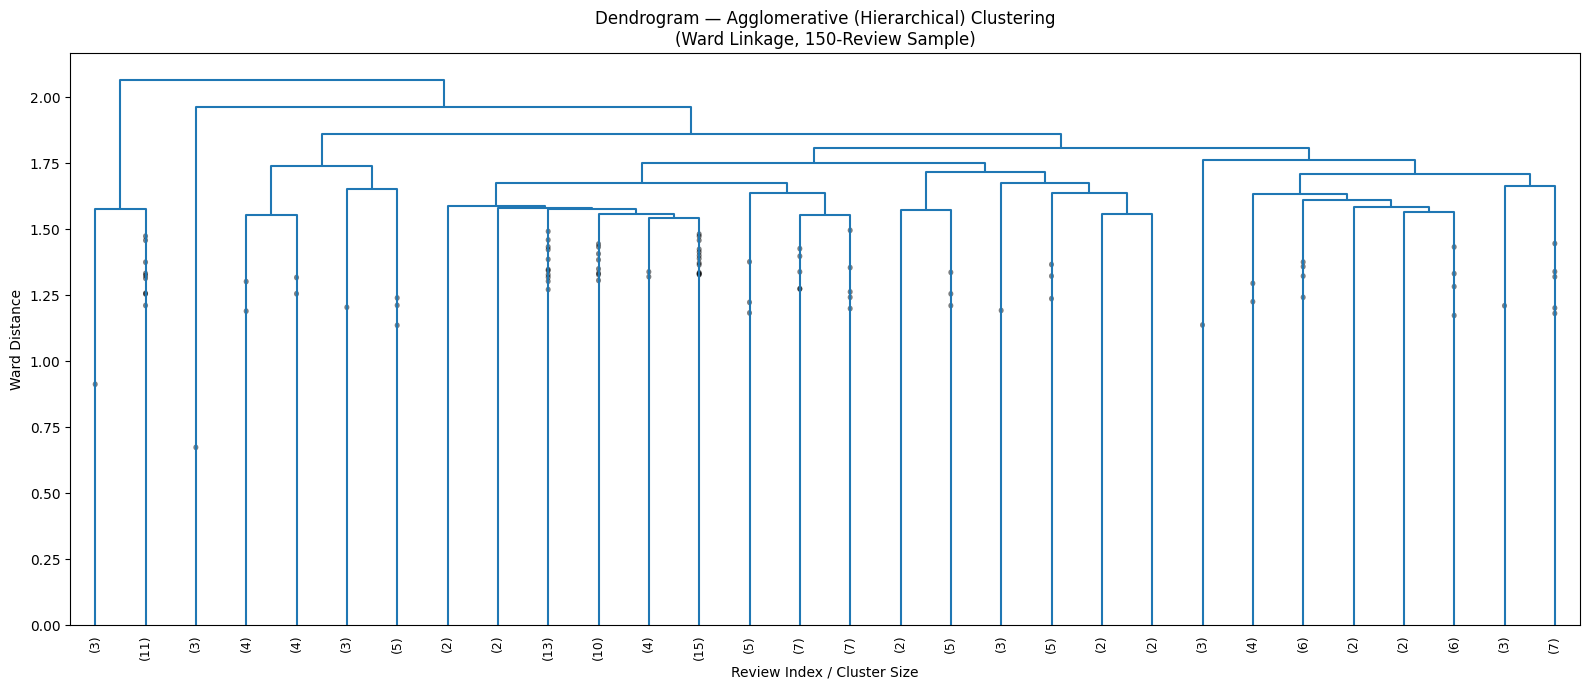

In [ ]:
#  Dendrogram for Agglomerative Clustering
from scipy.cluster.hierarchy import dendrogram, linkage

X_cluster_dense = X_cluster.toarray()

# Use a small sample to make dendrogram  readable
sample_idx = np.random.RandomState(42).choice(X_cluster_dense.shape[0], size=150, replace=False)
X_dendro = X_cluster_dense[sample_idx]

# Compute linkage matrix using Ward's method
linked = linkage(X_dendro, method='ward')

plt.figure(figsize=(16, 7))
dendrogram(
    linked,
    truncate_mode='lastp',
    p=30,
    leaf_rotation=90,
    leaf_font_size=9,
    show_contracted=True
)
plt.title("Dendrogram — Agglomerative (Hierarchical) Clustering\n(Ward Linkage, 150-Review Sample)")
plt.xlabel("Review Index / Cluster Size")
plt.ylabel("Ward Distance")
plt.tight_layout()
plt.show()

**Dendrogram analysis**

The dendrogram illustrates how individual reviews are progressively merged into clusters using Ward’s linkage, which minimizes within-cluster variance at each step. While larger vertical distances typically indicate meaningful separation between groups, the relatively gradual increases in Ward distance in this case suggest that the data do not have sharply distinct clusters but rather a continuous structure. However, by examining the higher-level merges, the data can still be reasonably partitioned into approximately 4–6 clusters, supporting the choice of K = 5 as a balanced segmentation. Reviews that merge at lower distances are highly similar in terms of vocabulary and themes, whereas those combined at higher distances reflect more distinct patterns.


(3000, 2)


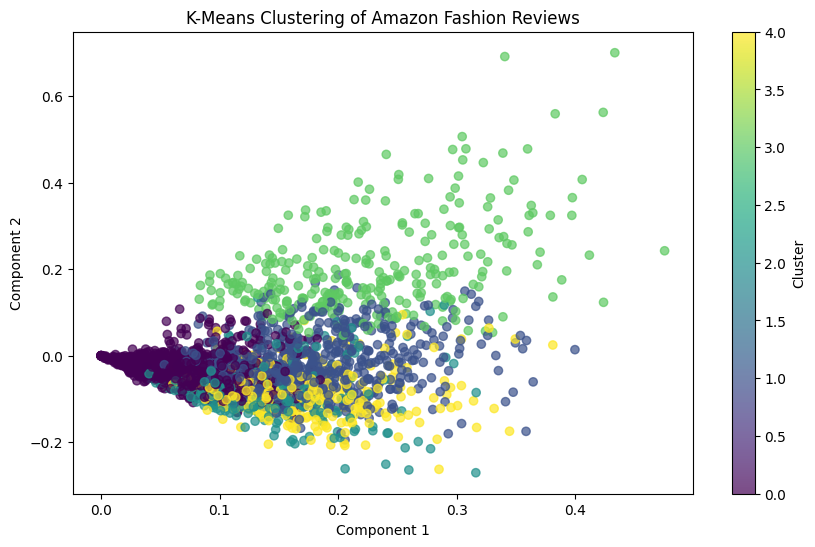

In [ ]:
## Reduce dimensions for visualization
svd = TruncatedSVD(n_components=2, random_state=42)
X_cluster_2d = svd.fit_transform(X_cluster)

print(X_cluster_2d.shape)

## visualize k-means clusters
plt.figure(figsize=(10, 6))
scatter = plt.scatter(
    X_cluster_2d[:, 0],
    X_cluster_2d[:, 1],
    c=cluster_df['kmeans_cluster'],
    cmap='viridis',
    alpha=0.7
)
plt.title("K-Means Clustering of Amazon Fashion Reviews")
plt.xlabel("Component 1")
plt.ylabel("Component 2")
plt.colorbar(scatter, label='Cluster')
plt.show()






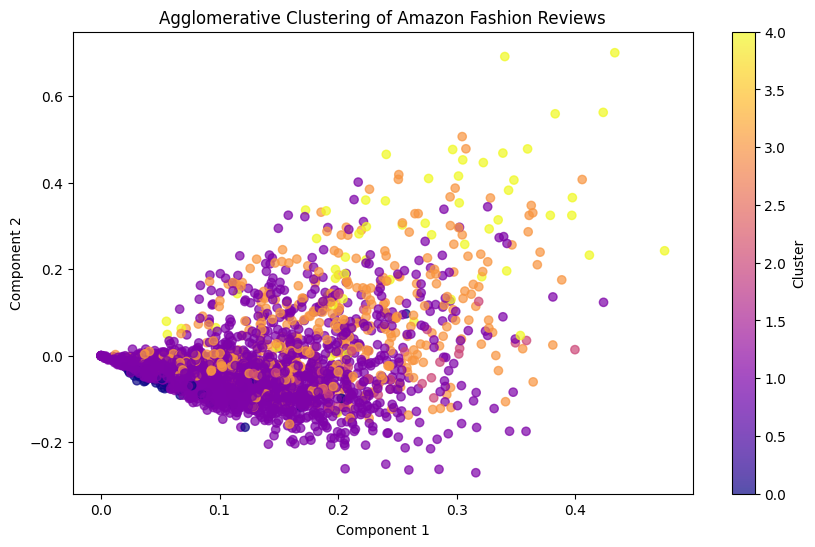

In [ ]:
## visualize Agglomentrative clusters
plt.figure(figsize=(10, 6))
scatter = plt.scatter(
    X_cluster_2d[:, 0],
    X_cluster_2d[:, 1],
    c=cluster_df['agg_cluster'],
    cmap='plasma',
    alpha=0.7
)
plt.title("Agglomerative Clustering of Amazon Fashion Reviews")
plt.xlabel("Component 1")
plt.ylabel("Component 2")
plt.colorbar(scatter, label='Cluster')
plt.show()

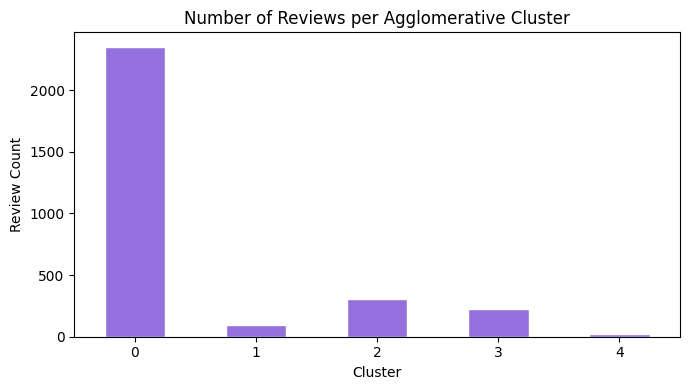

agg_cluster
0    2351
1      92
2     308
3     228
4      21
Name: count, dtype: int64


In [ ]:
# Agglomerative Cluster Size Distribution

X_cluster_dense = X_cluster.toarray()
agg = AgglomerativeClustering(n_clusters=5)
cluster_df['agg_cluster'] = agg.fit_predict(X_cluster_dense)

agg_counts = cluster_df['agg_cluster'].value_counts().sort_index()

plt.figure(figsize=(7, 4))
agg_counts.plot(kind='bar', color='mediumpurple', edgecolor='white')
plt.title("Number of Reviews per Agglomerative Cluster")
plt.xlabel("Cluster")
plt.ylabel("Review Count")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

print(agg_counts)

**Agglomerative and K-Means Comparison**

Both clustering methods produced five clusters but differ in their underlying approach and resulting structure. K-Means assigns each point to the nearest centroid, producing relatively compact and well-defined clusters that are efficient for large datasets. In contrast, Agglomerative clustering builds clusters hierarchically without predefined centroids, allowing it to capture more flexible, non-spherical structures but often resulting in less clearly separated groups and higher computational cost.

 Comparing the scatter plots, both methods reveal a similar overall structure, characterized by a dense central concentration of reviews and a few more dispersed groups. However, neither method produces perfectly balanced clusters, reflecting the continuous nature of the data. For this dataset, K-Means is preferred due to its scalability and clearer segmentation, while Agglomerative clustering serves as a useful validation technique, confirming that five clusters provide a reasonable and consistent grouping of the data


##  3.Text Classification Using Machine Learning

**Goal:** Train and compare 5 classifiers to predict review sentiment.

**Models trained:**
1. Naive Bayes
2. Support Vector Machine (SVM)
3. Decision Tree
4. Random Forest
5. AdaBoost

In [ ]:
# preparing data for classification
class_df = df.copy()

X = class_df['clean_text']
y = class_df['target']

In [ ]:
# Train test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training size:", X_train.shape)
print("Test size:", X_test.shape)

Training size: (538880,)
Test size: (134720,)


In [ ]:
# TF-IDF for classification
clf_vectorizer = TfidfVectorizer(stop_words='english', max_features=3000)

X_train_tfidf = clf_vectorizer.fit_transform(X_train)
X_test_tfidf = clf_vectorizer.transform(X_test)

print("X_train_tfidf:", X_train_tfidf.shape)
print("X_test_tfidf:", X_test_tfidf.shape)

X_train_tfidf: (538880, 3000)
X_test_tfidf: (134720, 3000)


In [ ]:
# Define models
models = {
    "Naive Bayes": MultinomialNB(),
    "SVM": LinearSVC(),
    "Decision Tree": DecisionTreeClassifier(max_depth=20, min_samples_split=10, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, max_depth=20, random_state=42, n_jobs=-1, class_weight='balanced'),
    "AdaBoost": AdaBoostClassifier(n_estimators=50, random_state=42)
}

In [ ]:
# Train and evaluate models
results = []

for name, model in models.items():
    print(f"\nTraining {name}...")

    model.fit(X_train_tfidf, y_train)
    y_pred = model.predict(X_test_tfidf)

    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, average='weighted', zero_division=0)
    rec = recall_score(y_test, y_pred, average='weighted', zero_division=0)
    f1 = f1_score(y_test, y_pred, average='weighted', zero_division=0)

    results.append({
        "Model": name,
        "Accuracy": acc,
        "Precision": prec,
        "Recall": rec,
        "F1-score": f1
    })

    print("Accuracy:", round(acc, 4))
    print("Precision:", round(prec, 4))
    print("Recall:", round(rec, 4))
    print("F1-score:", round(f1, 4))


Training Naive Bayes...
Accuracy: 0.6492
Precision: 0.6138
Recall: 0.6492
F1-score: 0.5902

Training SVM...
Accuracy: 0.6703
Precision: 0.6339
Recall: 0.6703
F1-score: 0.6207

Training Decision Tree...
Accuracy: 0.5966
Precision: 0.5481
Recall: 0.5966
F1-score: 0.5407

Training Random Forest...
Accuracy: 0.6271
Precision: 0.6074
Recall: 0.6271
F1-score: 0.614

Training AdaBoost...
Accuracy: 0.5587
Precision: 0.4355
Recall: 0.5587
F1-score: 0.4712


In [ ]:
# Results
results_df = pd.DataFrame(results).sort_values(by='F1-score', ascending=False)
results_df

,Model,Accuracy,Precision,Recall,F1-score
1,SVM,0.670287,0.633863,0.670287,0.620745
3,Random Forest,0.627138,0.607431,0.627138,0.613975
0,Naive Bayes,0.649191,0.613769,0.649191,0.590151
2,Decision Tree,0.596600,0.548137,0.596600,0.540723
4,AdaBoost,0.558692,0.435526,0.558692,0.471247


**Models analysis and interpretation**

The results show that the SVM model performs best overall, achieving the highest accuracy (0.67), recall (0.67), and F1-score (0.62), indicating it provides the most balanced performance in correctly identifying and classifying the review data. Naive Bayes follows closely, with solid accuracy (0.65) and recall (0.65), though its lower F1-score (0.59) suggests a slightly weaker balance between precision and recall. Random Forest performs moderately well, with an accuracy of 0.63 and an F1-score of 0.61, making it a competitive but slightly less optimal choice compared to SVM.

In contrast, Decision Tree and AdaBoost underperform, with lower scores across all metrics, particularly AdaBoost, which shows the weakest precision (0.44) and F1-score (0.47), indicating poorer classification reliability. Overall, the results suggest that SVM is the most effective model for this task, likely due to its strength in handling high-dimensional text data such as TF-IDF features, while ensemble and tree-based methods do not capture the patterns in the data as effectively in this case.





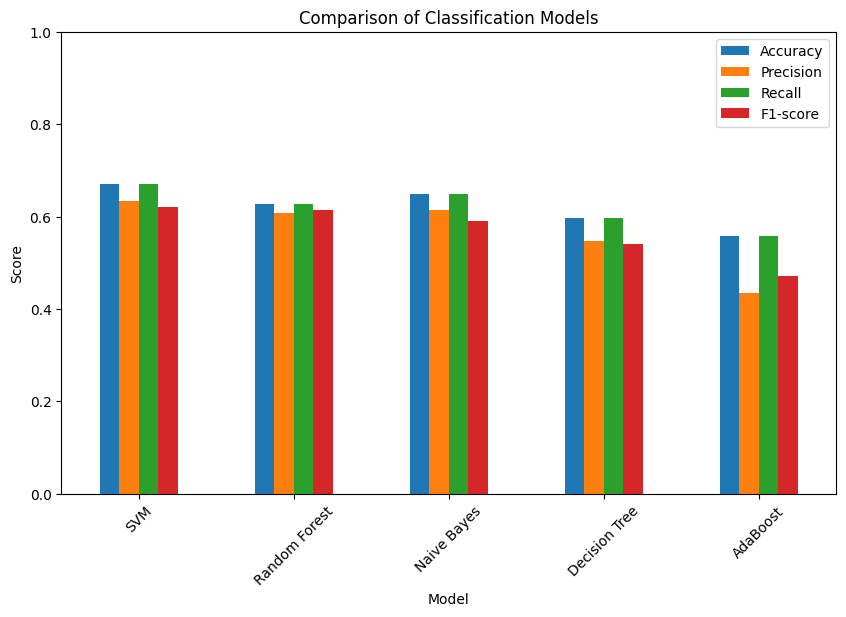

In [ ]:
# Visualize model comparison
results_df.set_index("Model")[["Accuracy", "Precision", "Recall", "F1-score"]].plot(
    kind='bar',
    figsize=(10, 6)
)

plt.title("Comparison of Classification Models")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=45)
plt.show()

In [ ]:
# Classification report for best model
best_model_name = results_df.iloc[0]['Model']
best_model = models[best_model_name]

y_pred_best = best_model.predict(X_test_tfidf)

print("Best Model:", best_model_name)
print("\nClassification Report:\n")
print(classification_report(y_test, y_pred_best))

Best Model: SVM

Classification Report:

              precision    recall  f1-score   support

        -1.0       0.69      0.88      0.77     62207
         0.0       0.48      0.12      0.19     31482
         1.0       0.67      0.77      0.72     41031

    accuracy                           0.67    134720
   macro avg       0.61      0.59      0.56    134720
weighted avg       0.63      0.67      0.62    134720



**Analysis**

The classification report for the SVM model shows an overall accuracy of 0.67, confirming it as the best-performing model among those tested. However, performance varies significantly across classes. The model performs well on the -1 (negative) class, with high recall (0.88) and a strong F1-score (0.77), indicating it is very effective at identifying negative reviews. It also performs solidly on the 1 (positive) class, achieving good precision (0.67), recall (0.77), and an F1-score of 0.72.

 In contrast, the model struggles with the 0 (neutral) class, where recall is very low (0.12), and the F1-score drops to 0.19, suggesting that neutral reviews are often misclassified as either positive or negative. The macro average F1-score of 0.56 reflects this imbalance in performance across classes, while the weighted F1-score of 0.62 indicates that the model performs better overall due to stronger results in the more dominant classes. Overall, the SVM model is effective for distinguishing positive and negative sentiment but has limited ability to accurately detect neutral reviews, highlighting a potential area for improvement.


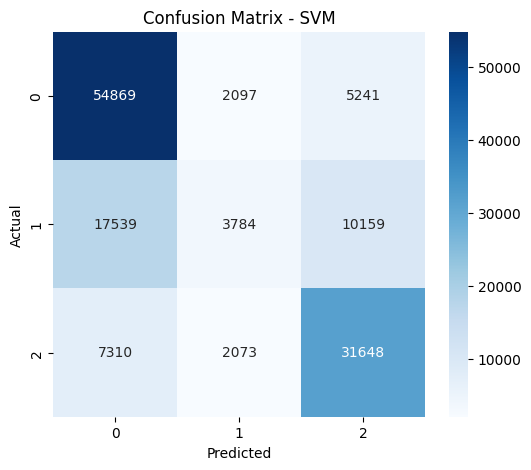

In [ ]:
# Confusion matrix for best model
cm = confusion_matrix(y_test, y_pred_best)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title(f"Confusion Matrix - {best_model_name}")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

Confusion analysis Interpretation


The confusion matrix for the SVM model shows strong performance in correctly classifying negative (class 0) and positive (class 2) reviews, but clear difficulty with the neutral (class 1) category. For negative reviews, the model correctly predicts a large majority (54,869), with relatively fewer misclassifications into positive (5,241) and neutral (2,097), indicating high recall and reliability for this class. Similarly, for positive reviews, most instances are correctly identified (31,648), though some are incorrectly labeled as negative (7,310) or neutral (2,073).

The main weakness appears in the neutral class, where only 3,784 reviews are correctly classified, while a substantial number are misclassified as negative (17,539) or positive (10,159). This confirms that the model struggles to distinguish neutral sentiment, often pushing those reviews toward the more dominant positive or negative categories. Overall, the matrix reinforces earlier findings: the SVM model is effective at identifying clear sentiment extremes but has limited ability to accurately capture neutral or ambiguous reviews, which impacts its overall balance despite a relatively good accuracy score


** Deep Learning Model (LSTM)**

In [ ]:
# Prepare labels for LSTM

dl_df = df.sample(n=30000, random_state=42).copy()

X_dl = dl_df['clean_text']
y_dl = dl_df['target'].map({-1: 0, 1: 1})


In [ ]:
# Train-test split for LSTM

# Filter out NaN values from y_dl and corresponding X_dl
valid_indices = y_dl.dropna().index
X_dl_filtered = X_dl.loc[valid_indices]
y_dl_filtered = y_dl.loc[valid_indices]

X_train_dl, X_test_dl, y_train_dl, y_test_dl = train_test_split(
    X_dl_filtered,
    y_dl_filtered,
    test_size=0.2,
    random_state=42,
    stratify=y_dl_filtered
)

In [ ]:
# Tokenize and pad sequences
max_words = 5000
max_len = 80

tokenizer = Tokenizer(num_words=max_words, oov_token="<OOV>")
tokenizer.fit_on_texts(X_train_dl)

X_train_seq = tokenizer.texts_to_sequences(X_train_dl)
X_test_seq = tokenizer.texts_to_sequences(X_test_dl)

X_train_pad = pad_sequences(X_train_seq, maxlen=max_len, padding='post', truncating='post')
X_test_pad = pad_sequences(X_test_seq, maxlen=max_len, padding='post', truncating='post')

print(X_train_pad.shape, X_test_pad.shape)

(18367, 80) (4592, 80)


In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Embedding, LSTM, Dense

lstm_model = Sequential([
    Input(shape=(max_len,)),
    Embedding(input_dim=max_words, output_dim=32),
    LSTM(32),
    Dense(1, activation='sigmoid')
])

lstm_model.compile(
    loss='binary_crossentropy',
    optimizer='adam',
    metrics=['accuracy']
)

lstm_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 80, 32)         │       160,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 32)             │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 168,353 (657.63 KB)

 Trainable params: 168,353 (657.63 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# Train LSTM
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=1,
    restore_best_weights=True
)

history = lstm_model.fit(
    X_train_pad,
    y_train_dl,
    validation_split=0.2,
    epochs=3,
    batch_size=128,
    callbacks=[early_stop]
)

Epoch 1/3
115/115 ━━━━━━━━━━━━━━━━━━━━ 11s 68ms/step - accuracy: 0.6078 - loss: 0.6699 - val_accuracy: 0.5863 - val_loss: 0.6774
Epoch 2/3
115/115 ━━━━━━━━━━━━━━━━━━━━ 9s 75ms/step - accuracy: 0.6100 - loss: 0.6681 - val_accuracy: 0.5863 - val_loss: 0.6777


In [ ]:
# Evaluate LSTM
y_pred_prob = lstm_model.predict(X_test_pad)
y_pred_lstm = (y_pred_prob > 0.5).astype(int).flatten()

lstm_acc = accuracy_score(y_test_dl, y_pred_lstm)
lstm_prec = precision_score(y_test_dl, y_pred_lstm, average='weighted')
lstm_rec = recall_score(y_test_dl, y_pred_lstm, average='weighted')
lstm_f1 = f1_score(y_test_dl, y_pred_lstm, average='weighted')

print("LSTM Accuracy:", round(lstm_acc, 4))
print("LSTM Precision:", round(lstm_prec, 4))
print("LSTM Recall:", round(lstm_rec, 4))
print("LSTM F1-score:", round(lstm_f1, 4))

144/144 ━━━━━━━━━━━━━━━━━━━━ 3s 21ms/step
LSTM Accuracy: 0.6052
LSTM Precision: 0.3662
LSTM Recall: 0.6052
LSTM F1-score: 0.4563


In [ ]:
# LSTM classification report
print(classification_report(y_test_dl, y_pred_lstm))

              precision    recall  f1-score   support

         0.0       0.61      1.00      0.75      2779
         1.0       0.00      0.00      0.00      1813

    accuracy                           0.61      4592
   macro avg       0.30      0.50      0.38      4592
weighted avg       0.37      0.61      0.46      4592



In [ ]:
# Merge LSTM with traditional model results
lstm_result = pd.DataFrame([{
    "Model": "LSTM",
    "Accuracy": lstm_acc,
    "Precision": lstm_prec,
    "Recall": lstm_rec,
    "F1-score": lstm_f1
}])

results_df_all = pd.concat([results_df, lstm_result], ignore_index=True)
results_df_all = results_df_all.sort_values(by='F1-score', ascending=False)

results_df_all

,Model,Accuracy,Precision,Recall,F1-score
0,SVM,0.670287,0.633863,0.670287,0.620745
1,Random Forest,0.627138,0.607431,0.627138,0.613975
2,Naive Bayes,0.649191,0.613769,0.649191,0.590151
3,Decision Tree,0.596600,0.548137,0.596600,0.540723
4,AdaBoost,0.558692,0.435526,0.558692,0.471247
5,LSTM,0.605183,0.366246,0.605183,0.456330


**Interpretation**

The results show that SVM remains the best-performing model, achieving the highest accuracy (0.67), recall (0.67), and F1-score (0.62), indicating the most balanced overall performance on the dataset. Naive Bayes follows with strong accuracy (0.65) and recall (0.65), though its lower F1-score (0.59) suggests a slightly weaker balance between precision and recall. Random Forest performs competitively with an accuracy of 0.63 and an F1-score of 0.61, making it a solid alternative but still slightly behind SVM.

The Decision Tree model shows moderate performance, with lower scores across all metrics, while AdaBoost and LSTM perform the worst, particularly in precision and F1-score. The LSTM model has very low precision (0.37) and a weak F1-score (0.46), indicating it struggles to generalize effectively in this setup, likely due to insufficient tuning or data representation compared to TF-IDF-based models. Overall, the results suggest that traditional machine learning models, particularly SVM, are more effective for this text classification task than both tree-based ensembles and the neural network approach used here.


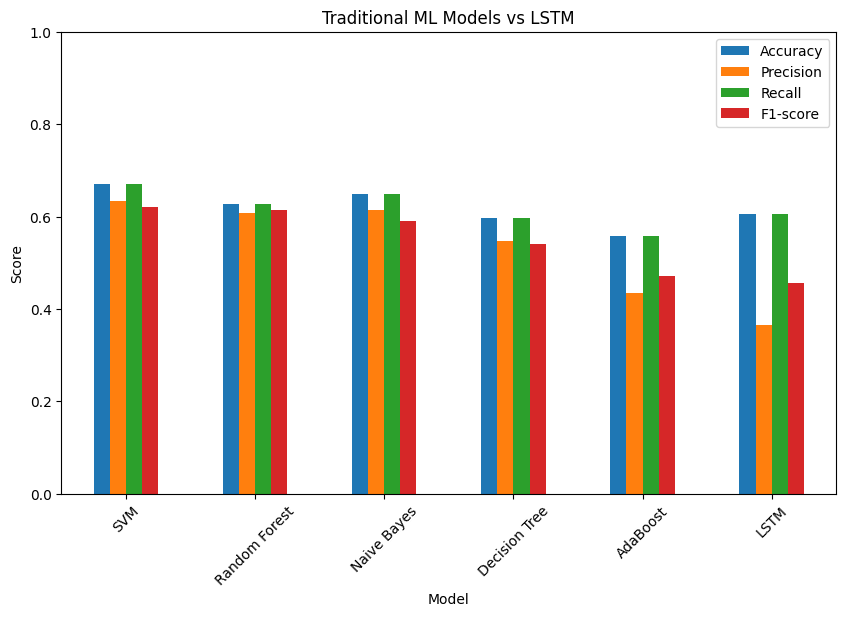

In [ ]:
# Visualize all models together
results_df_all.set_index("Model")[["Accuracy", "Precision", "Recall", "F1-score"]].plot(
    kind='bar',
    figsize=(10, 6)
)

plt.title("Traditional ML Models vs LSTM")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=45)
plt.show()